# **Лабораторная 5. Аналитическое моделирование тренда и случайных остатков**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Построить несколько регрессионных моделей тренда, выбрать лучшую и построить по ней прогноз на следующий шаг
2. Построить ARIMA-модель случайных остатков ряда и совокупный прогноз на следующий шаг

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')

## Данные *(Вариант 16)*

Тот же ряд, что в лабораторной 4: просроченная кредиторская задолженность организаций поставщикам и подрядчикам на конец года за 1995–2021 гг., млрд руб.

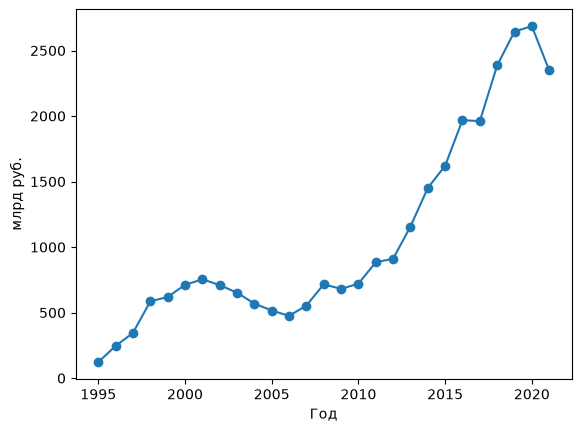

In [2]:
raw = pd.read_excel('fin_sost_org.xlsx.ods', engine='odf', sheet_name='4', header=None)
y = raw.iloc[6:33].set_index(1)[5].astype(float)
y.index = y.index.astype(int)
y.index.name = 'Год'
n = len(y)
t = np.arange(1, n + 1)
next_year = y.index[-1] + 1

plt.plot(y, marker='o')
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.show()

## 5.1. Регрессионные модели тренда

### Модели

Регрессор — номер года $t = 1, \dots, 27$. Нелинейные модели линеаризую заменой переменных и оцениваю методом наименьших квадратов:

| Модель | Вид | Линеаризация |
|---|---|---|
| Линейная | $y = a + bt$ | — |
| Квадратичная | $y = a + bt + ct^2$ | $x_1 = t,\ x_2 = t^2$ |
| Кубическая | $y = a + bt + ct^2 + dt^3$ | $x_1 = t,\ x_2 = t^2,\ x_3 = t^3$ |
| Логарифмическая | $y = a + b \ln t$ | $x = \ln t$ |
| Гиперболическая | $y = a + b / t$ | $x = 1 / t$ |
| Экспоненциальная | $y = e^{a + bt}$ | $\ln y = a + bt$ |
| Степенная | $y = a t^b$ | $\ln y = \ln a + b \ln t$ |

Чтобы модели можно было сравнивать, $R^2$ считаю по исходному ряду, а не по логарифмам.
$$R^2 = 1 - \frac{\sum (y_t - \hat{y}_t)^2}{\sum (y_t - \bar{y})^2}, \qquad R^2_{скорр} = 1 - (1 - R^2)\frac{n - 1}{n - k - 1}$$

In [3]:
forms = {
    'Линейная': (lambda t: t, False),
    'Квадратичная': (lambda t: np.column_stack([t, t ** 2]), False),
    'Кубическая': (lambda t: np.column_stack([t, t ** 2, t ** 3]), False),
    'Логарифмическая': (lambda t: np.log(t), False),
    'Гиперболическая': (lambda t: 1 / t, False),
    'Экспоненциальная': (lambda t: t, True),
    'Степенная': (lambda t: np.log(t), True),
}


def fit_trend(name, values, times):
    make, log = forms[name]
    target = np.log(values) if log else values
    return sm.OLS(target, sm.add_constant(make(times))).fit()


def predict_trend(name, model, times):
    make, log = forms[name]
    pred = model.predict(sm.add_constant(make(times), has_constant='add'))
    return np.exp(pred) if log else pred


fits, rows = {}, []
for name in forms:
    model = fit_trend(name, y, t)
    fitted = predict_trend(name, model, t)
    r2 = 1 - ((y.to_numpy() - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    adj = 1 - (1 - r2) * (n - 1) / (n - model.df_model - 1)
    fits[name] = model
    rows.append([name, r2, adj, model.f_pvalue])

results = pd.DataFrame(rows, columns=['Модель', 'R²', 'R² скорр.', 'p-value F']).set_index('Модель')
results.sort_values('R² скорр.', ascending=False).round(4)

,R²,R² скорр.,p-value F
Модель,,,
Кубическая,0.9323,0.9234,0.0000
Квадратичная,0.9175,0.9106,0.0000
Экспоненциальная,0.9025,0.8986,0.0000
Линейная,0.7835,0.7749,0.0000
Степенная,0.6654,0.6520,0.0000
Логарифмическая,0.5319,0.5132,0.0000
Гиперболическая,0.2384,0.2080,0.0098


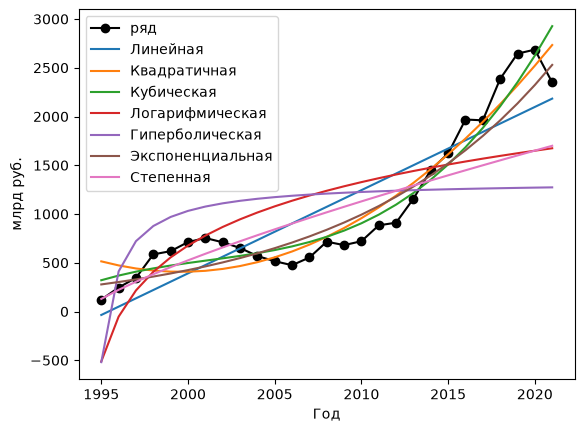

In [4]:
plt.plot(y, marker='o', color='black', label='ряд')
for name in forms:
    plt.plot(y.index, predict_trend(name, fits[name], t), label=name)
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.legend()
plt.show()

In [5]:
best = results['R² скорр.'].idxmax()
model = fits[best]
print(best)
pd.DataFrame({'Коэффициент': model.params, 'p-value': model.pvalues}).round(4)

Кубическая


,Коэффициент,p-value
const,263.9524,0.1749
x1,62.0408,0.2899
x2,-5.3423,0.2681
x3,0.2480,0.0349


Наибольший скорректированный R² у кубической модели — 0.923, она объясняет 93% дисперсии ряда. Квадратичная и экспоненциальная немного хуже (0.911 и 0.899). Все модели значимы по критерию Фишера (p-value < 0.05). У кубической модели значим только коэффициент при $t^3$, остальные коэффициенты по отдельности незначимы.

### Проверка остатков

Для выбранной модели проверяю условия теоремы Гаусса–Маркова:
1. нормальность остатков — критерий Шапиро–Уилка, $H_0$: остатки распределены нормально;
2. гомоскедастичность — критерий Бройша–Пагана, $H_0$: дисперсия остатков постоянна;
3. отсутствие автокорреляции — критерий Дарбина–Уотсона, значение около 2 означает отсутствие автокорреляции.

Шапиро–Уилк: p-value = 0.0791
Бройш–Паган: p-value = 0.0045
Дарбин–Уотсон: 0.72


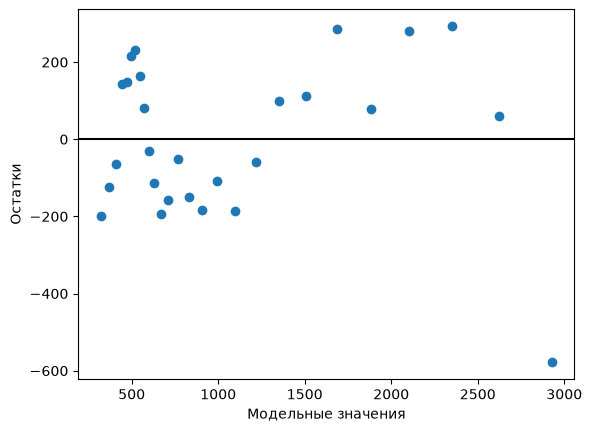

In [6]:
resid = model.resid
print(f'Шапиро–Уилк: p-value = {stats.shapiro(resid).pvalue:.4f}')
print(f'Бройш–Паган: p-value = {het_breuschpagan(resid, model.model.exog)[1]:.4f}')
print(f'Дарбин–Уотсон: {durbin_watson(resid):.2f}')

plt.scatter(model.fittedvalues, resid)
plt.axhline(0, color='black')
plt.xlabel('Модельные значения')
plt.ylabel('Остатки')
plt.show()

Шапиро–Уилк: p-value = 0.079 > 0.05, остатки можно считать нормальными. Бройш–Паган: p-value = 0.0045 < 0.05, остатки гетероскедастичны — их разброс растёт вместе с уровнем ряда. Дарбин–Уотсон 0.72 намного меньше 2: в остатках сильная положительная автокорреляция, соседние остатки близки друг к другу, т.е. модель не учитывает отдельные периоды роста и спада ряда. Условия Гаусса–Маркова выполнены не все, поэтому кубическая модель описывает общую тенденцию, а прогнозу по ней нужно доверять осторожно.

### Прогноз

Прогноз на 2022 г.: 3257.9


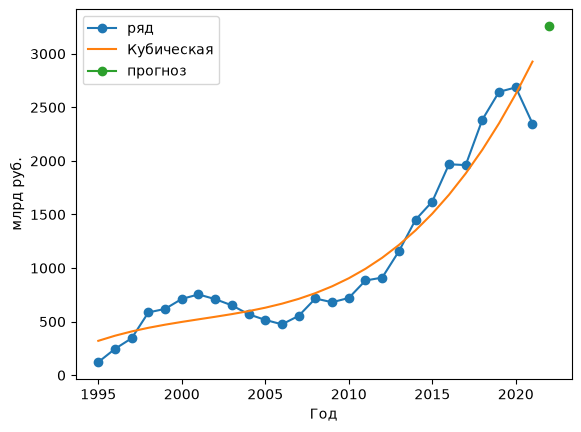

In [7]:
trend_forecast = predict_trend(best, model, np.array([n + 1]))[0]
print(f'Прогноз на {next_year} г.: {trend_forecast:.1f}')

plt.plot(y, marker='o', label='ряд')
plt.plot(y.index, predict_trend(best, model, t), label=best)
plt.plot(next_year, trend_forecast, marker='o', label='прогноз')
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.legend()
plt.show()

### Результат

Лучшая модель тренда — кубическая. Прогноз на 2022 г. — 3257.9 млрд руб. При экстраполяции кубический полином продолжает рост, хотя в 2021 г. задолженность снизилась с 2686 до 2349 млрд руб.

## 5.2. ARIMA-модель случайных остатков

### Декомпозиция ряда

Раскладываю ряд по аддитивной модели на тренд, квазисезон с периодом 2 и случайные остатки: $y_t = T_t + S_t + E_t$. Квазисезон — поправочная константа со знаком плюс или минус в зависимости от чётности года. Тренд при декомпозиции — скользящее среднее, поэтому на краях ряда тренда и остатков нет.

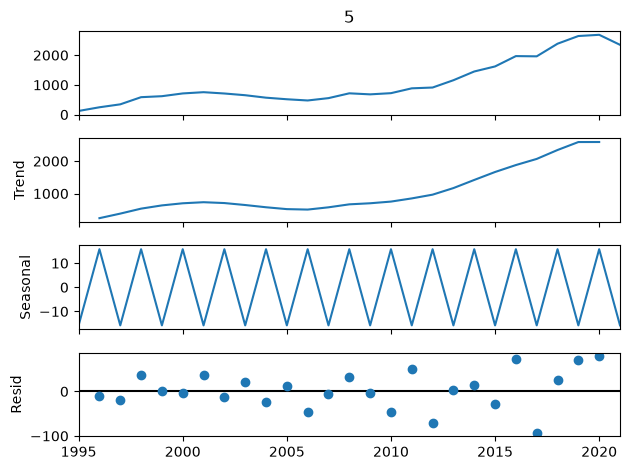

Квазисезон: -15.77 и 15.77


In [8]:
decomposition = seasonal_decompose(y, model='additive', period=2)
decomposition.plot()
plt.show()

trend = decomposition.trend.dropna()
season = decomposition.seasonal
noise = decomposition.resid.dropna()
print(f'Квазисезон: {season.iloc[0]:.2f} и {season.iloc[1]:.2f}')

### Модель тренда

Тренд из декомпозиции моделирую моделью того же вида, что выбрана в пункте 5.1.

In [9]:
t_trend = t[decomposition.trend.notna().to_numpy()]
trend_model = fit_trend(best, trend, t_trend)
trend_part = predict_trend(best, trend_model, np.array([n + 1]))[0]
season_part = season.iloc[-2]
print(f'Тренд на {next_year} г.: {trend_part:.1f}')
print(f'Квазисезон на {next_year} г.: {season_part:.2f}')

Тренд на 2022 г.: 3712.0
Квазисезон на 2022 г.: 15.77


### Стационарность остатков

Методика Бокса–Дженкинса работает только со стационарными рядами. Проверяю остатки двумя критериями:
- расширенный тест Дики–Фуллера (ADF), $H_0$: ряд нестационарный;
- тест KPSS, $H_0$: ряд стационарный.

Тренд дисперсии проверяю методом Фостера–Стюарта из лабораторной 4.

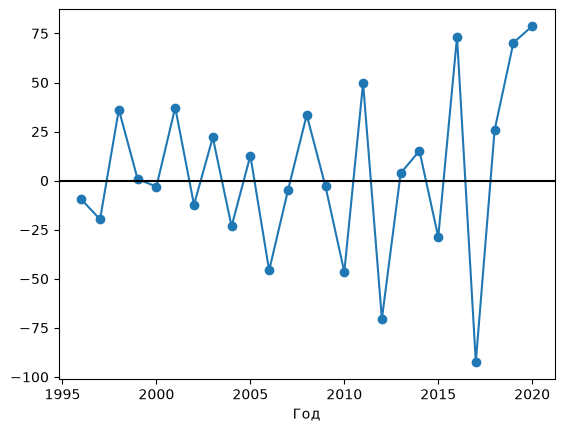

ADF: p-value = 0.0000
KPSS: p-value = 0.1000
Фостер–Стюарт: ts = 3.00, t табл = 2.06


In [10]:
plt.plot(noise, marker='o')
plt.axhline(0, color='black')
plt.xlabel('Год')
plt.show()

print(f'ADF: p-value = {adfuller(noise)[1]:.4f}')
print(f'KPSS: p-value = {kpss(noise, regression="c")[1]:.4f}')

m = len(noise)
k = [int(noise.iloc[i] > noise.iloc[:i].max()) for i in range(1, m)]
l = [int(noise.iloc[i] < noise.iloc[:i].min()) for i in range(1, m)]
mu = 2 * sum(1 / i for i in range(2, m + 1))
sigma2 = np.sqrt(mu - 4 * sum(1 / i ** 2 for i in range(2, m + 1)))
ts = abs(sum(k) + sum(l) - mu) / sigma2
print(f'Фостер–Стюарт: ts = {ts:.2f}, t табл = {stats.t.ppf(0.975, m - 1):.2f}')

ADF: p-value < 0.05, гипотеза о нестационарности отвергается. KPSS: p-value = 0.1 > 0.05, гипотеза о стационарности не отвергается. По обоим тестам остатки стационарны в среднем. Но по Фостеру–Стюарту $t_s$ = 3.00 больше табличного 2.06: у остатков есть тренд дисперсии, к концу ряда разброс растёт вместе с уровнем. По методике дисперсию следовало бы стабилизировать преобразованием Бокса–Кокса, но оно требует положительных значений, а остатки бывают отрицательными, поэтому модель строю по исходным остаткам.

### Выбор ARIMA-модели

Порядки модели оцениваю по автокорреляционной (ACF) и частной автокорреляционной (PACF) функциям, затем сравниваю несколько моделей ARIMA(p, 0, q) по информационному критерию Акаике AIC: чем он меньше, тем лучше модель.

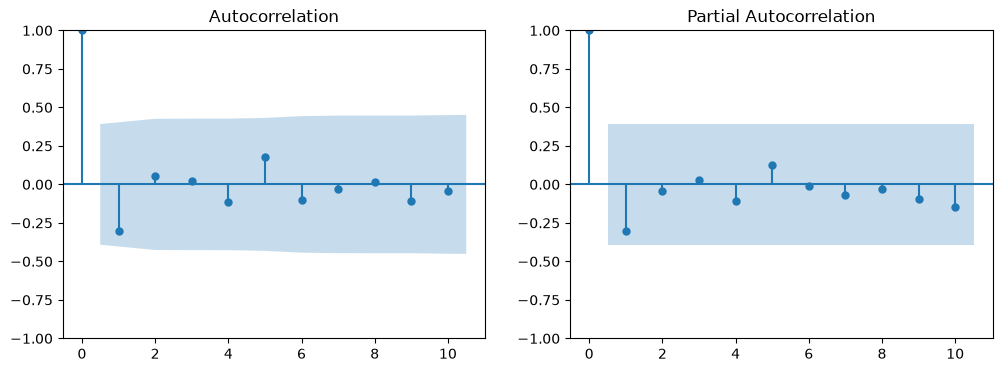

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(noise, ax=ax[0], lags=10)
plot_pacf(noise, ax=ax[1], lags=10)
plt.show()

In [12]:
aic = {}
for p in range(3):
    for q in range(3):
        aic[(p, q)] = ARIMA(noise.to_numpy(), order=(p, 0, q)).fit().aic

best_p, best_q = min(aic, key=aic.get)
pd.Series({f'ARIMA({p}, 0, {q})': value for (p, q), value in aic.items()}).sort_values().round(2)

ARIMA(0, 0, 1)    260.48
ARIMA(1, 0, 0)    261.02
ARIMA(0, 0, 0)    261.65
ARIMA(1, 0, 1)    262.45
ARIMA(0, 0, 2)    262.45
ARIMA(2, 0, 0)    262.60
ARIMA(2, 0, 1)    263.14
ARIMA(1, 0, 2)    263.15
ARIMA(2, 0, 2)    265.13
dtype: float64

In [13]:
arima = ARIMA(noise.to_numpy(), order=(best_p, 0, best_q)).fit()
print(f'ARIMA({best_p}, 0, {best_q})')
print(f'Льюнг–Бокс: p-value = {acorr_ljungbox(arima.resid, lags=[5])["lb_pvalue"].iloc[0]:.4f}')

ARIMA(0, 0, 1)
Льюнг–Бокс: p-value = 0.9991


Значения ACF и PACF не выходят за доверительную область, остатки близки к белому шуму. Минимальный AIC у ARIMA(0, 0, 1) — 260.48, хотя AIC остальных моделей отличается мало. Тест Льюнга–Бокса: p-value = 0.999, остатки модели некоррелированы, модель можно использовать для прогноза.

### Совокупный прогноз

Остатки известны только до 2020 г., поэтому для 2022 г. беру прогноз ARIMA на 2 шага вперёд. Совокупный прогноз по аддитивной модели:
$$\hat{y} = \hat{T} + S + \hat{E}$$

In [14]:
steps = int(next_year - noise.index[-1])
noise_part = arima.forecast(steps=steps)[-1]
total_forecast = trend_part + season_part + noise_part
pd.Series({'Тренд': trend_part, 'Квазисезон': season_part, 'Остатки': noise_part,
           'Совокупный прогноз': total_forecast, 'Прогноз 5.1': trend_forecast}).round(1)

Тренд                 3712.0
Квазисезон              15.8
Остатки                  2.4
Совокупный прогноз    3730.2
Прогноз 5.1           3257.9
dtype: float64

### Результат

Совокупный прогноз на 2022 г. — 3730.2 млрд руб.: тренд 3712.0, квазисезон +15.8, остатки +2.4. Вклад квазисезона и остатков мал, прогноз определяется трендом. Тренд из декомпозиции известен только до 2020 г. и не учитывает спад 2021 г., поэтому прогноз выше, чем в пункте 5.1 (3257.9).

## Вывод

Из семи регрессионных моделей ряд лучше всего описывает кубическая (скорректированный R² = 0.923), прогноз по ней на 2022 г. — 3257.9 млрд руб. Но остатки модели гетероскедастичны и сильно автокоррелированы, так что модель передаёт общую тенденцию роста, а не колебания ряда. После декомпозиции случайные остатки стационарны в среднем и описываются моделью ARIMA(0, 0, 1), остатки которой некоррелированы. Совокупный прогноз по аддитивной модели — 3730.2 млрд руб. Оба прогноза предполагают продолжение роста: кубический тренд при экстраполяции быстро растёт и слабо учитывает спад 2021 г.